# Eksploracyjna Analiza Danych dla przetworzonych danych

## Importowanie bibliotek

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import os 
from datetime import datetime, timedelta
import seaborn as sns
import numpy as np
import scipy


## Ładowanie Danych

In [45]:
DATA_ARRAY = {}
directory = '../data/enriched'
for file in os.listdir(directory):
    file_path = os.path.join(directory,file)
    dates_from_filename = file.removesuffix('.csv').removeprefix('enriched-')
    finish_date = datetime.strptime(dates_from_filename, '%d-%m-%Y')
    start_date = finish_date - timedelta(days=5)
    df = pd.read_csv(file_path)
    DATA_ARRAY[start_date.strftime('%d-%m-%Y') + ' do ' + finish_date.strftime('%d-%m-%Y') ] = df

compacted_data = pd.concat(DATA_ARRAY)




## Wstępne analiza 

### Wymiary tabeli i podstawowe dane

In [46]:

print('Ilość kolumn:', compacted_data.shape[1])
print('Ilość wierszy:',compacted_data.shape[0])
print('Typy danych kolumn:')
print(compacted_data.dtypes,'\n')
print('Ilość wartości Nan:')
print(compacted_data)
    


Ilość kolumn: 15
Ilość wierszy: 1415
Typy danych kolumn:
date              object
link              object
title             object
content           object
company_name      object
ticker            object
category          object
source            object
initial price    float64
+5 min           float64
+10 min          float64
+15 min          float64
+30 min          float64
+60 min          float64
rate             float64
dtype: object 

Ilość wartości Nan:
                                             date  \
12-10-2026 do 17-10-2026 0    2026-10-15 10:59:00   
                         1    2026-10-15 10:51:00   
                         2    2026-10-14 14:55:00   
                         3    2026-10-15 10:27:00   
                         4    2026-10-15 10:22:00   
...                                           ...   
25-10-2026 do 30-10-2026 595  2026-10-27 11:26:39   
                         596  2026-10-27 09:11:01   
                         597  2026-10-27 08:33:06   
  

## Duplikaty

Ponieważ w poprzednie analizie danych, dokonaliśmy czysczenia poprzez usuwanie duplikatów w kolumnie z linkami, tytułami oraz zawartością. Tutaj tylko upewnimy się czy nie wkradły się niepożądane duplikaty.

### Sprawdzenie duplikatów w kolumnach link, title, content

In [47]:

print(f'-------------[link]-------------\n')
dups = compacted_data.pivot_table(index = ['link'], aggfunc ='size')
print(dups[dups > 1])
print(f'-------------[title]-------------\n')
dups = compacted_data.pivot_table(index = ['title'], aggfunc ='size')
print(dups[dups > 1])
print(f'-------------[content]-------------\n')
dups = compacted_data.pivot_table(index = ['content'], aggfunc ='size')
print(dups[dups > 1])




-------------[link]-------------

Series([], dtype: int64)
-------------[title]-------------

title
DZIEŃ NA GPW: Czwartkowa sesja może rozpocząć się od spadków         2
DZIEŃ NA RYNKACH: W Azji na giełdach indeksy się wahają              2
DZIEŃ NA RYNKACH: W Azji na giełdach wahania indeksów                2
DZIEŃ NA RYNKACH: W Europie na giełdach wahania indeksów             2
Najważniejsze indeksy giełdowe w Azji                                3
Notowania metali bazowych, węgla i paliw (tabela)                    3
Rentowności obligacji wybranych państw (tabela)                      3
Zamknięcia na giełdach w Ameryce Północnej i Południowej (tabela)    3
Zamknięcia na giełdach w Europie (tabela)                            3
dtype: int64
-------------[content]-------------

content
Notowania metali bazowych na London Metal Exchange, uprawnień EUA do emisji CO2, ceny węgla energetycznego ARA na przyszły rok oraz ceny paliw. (PAP Biznes) kek/                                          

Teraz mamy pewność, że pozbyliśmy się wszystkich duplikatów.

### Duplikaty w kolumnie company_name

In [48]:
print(f'-------------[company_name]-------------\n')
dups = compacted_data.pivot_table(index = ['company_name'], aggfunc ='size')
print(dups[dups > 1])

-------------[company_name]-------------

company_name
Nan          870
alior         20
allegro       15
budimex       48
cdprojekt     16
erste         25
kety          11
kghm          51
kruk          10
lpp            8
mbank         34
modivo         5
orangepl      15
pekao         26
pepco         18
pge           53
pknorlen     102
pkobp         50
pzu            8
zabka         26
dtype: int64


Widać, że wiele duplikatów wynika z nazewnictwa pustej komórki dla nie dopasownanych wiadomości ze spółek poprzez "Nan". Dzieje się tak, ponieważ model w swojej instrukcji ma podane aby konkretnie odpowiadać gdy nie może dopasować spółki "Nan". Jest to motywowanem tym, aby model nie halucynował i nie podawał "czegokolwiek", dlatego powstała dokładna instrukcja aby takim spółkom "nadawać nazwę Nan".

## Usuwanie wartości pustych

Aby mieć czyste dane gotowe do ewaluacji, najpierw z datasetu trzeba usunąć puste komórki. Będziemy działać na całym zbiorze danych


### Puste komórki w kolumnie company_name

In [49]:
compacted_data = compacted_data[compacted_data.company_name != "Nan"]
compacted_data['company_name'].dropna()
print(compacted_data['company_name'].unique())

print(compacted_data['company_name'].value_counts())


['erste' 'kghm' 'cdprojekt' 'pknorlen' 'pkobp' 'pge' 'pzu' 'alior' 'zabka'
 'allegro' 'pepco' 'pekao' 'budimex' 'kruk' 'lpp' 'kety' 'mbank' nan
 'orangepl' 'dinopl' 'modivo']
company_name
pknorlen     102
pge           53
kghm          51
pkobp         50
budimex       48
mbank         34
pekao         26
zabka         26
erste         25
alior         20
pepco         18
cdprojekt     16
orangepl      15
allegro       15
kety          11
kruk          10
pzu            8
lpp            8
modivo         5
dinopl         1
Name: count, dtype: int64


Teraz gdy pozbyliśmy się duplikatów i pustych komórek, można się przyjrzeć co i ile nam zostało.

## Wizualizacja danych podzielonych na kategorie i źródła 

### Wymiary danych dla poszczególnych źródeł

Kategorie economy, market i profiles należą do pap, technologia, finanse, gospodarka, inwestycje należą do wykop, a bankier jak sama nazwa wskazuję do bankier

In [51]:
print('-------Skumulowane dane-------\n')
print("Źródła:", compacted_data['source'].value_counts())
print()

print('Kategorie:', compacted_data['category'].value_counts())

-------Skumulowane dane-------

Źródła: source
pap        346
bankier    173
wykop       26
Name: count, dtype: int64

Kategorie: category
profiles       205
bankier        173
market          99
economy         42
technologia     10
gospodarka       9
finanse          5
inwestycje       2
Name: count, dtype: int64


## Wizualizacja danych

### Źródła

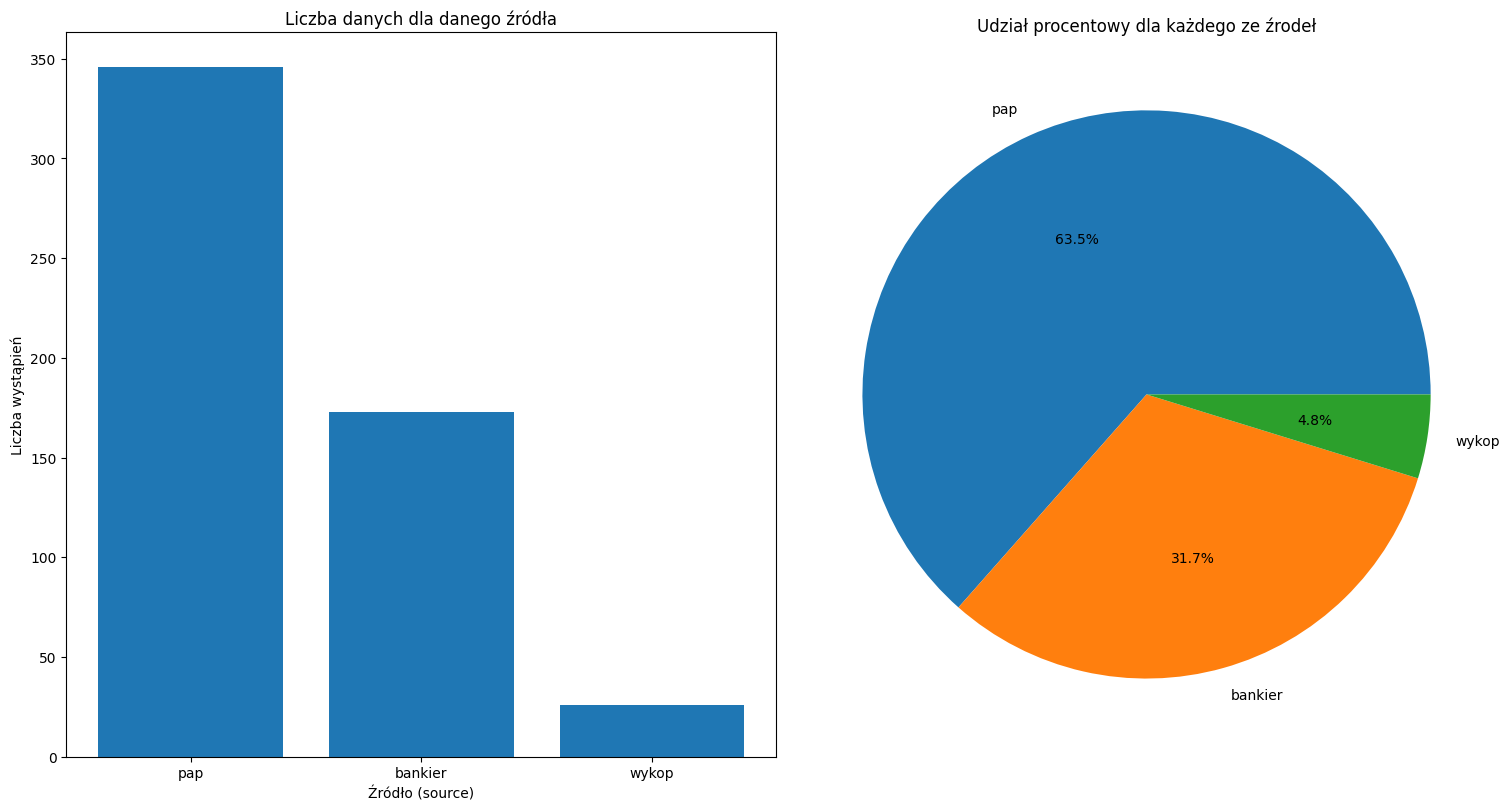

In [52]:
counts = compacted_data['source'].value_counts()

fig, ax = plt.subplots(1,2, figsize=(15,8), constrained_layout=True)
ax[0].bar(x=counts.index, height=counts.values,)
ax[0].set(xlabel = 'Źródło (source)', ylabel = 'Liczba wystąpień')
ax[0].set_title('Liczba danych dla danego źródła')
ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%')
ax[1].set_title('Udział procentowy dla każdego ze źrodeł')
plt.show()

### Kategorie Pap

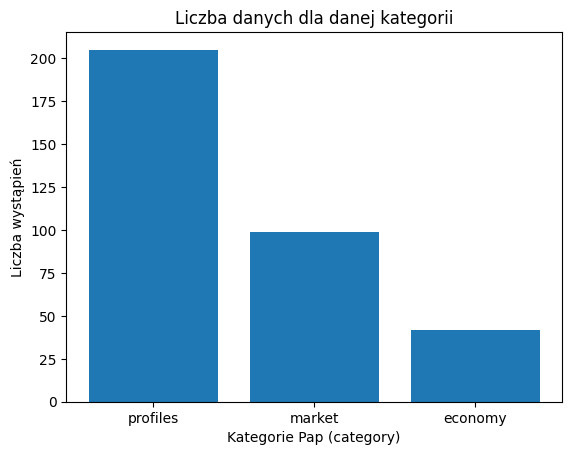

In [53]:
counts = compacted_data[compacted_data['source'] == 'pap']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Pap (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

### Kategoria Bankier

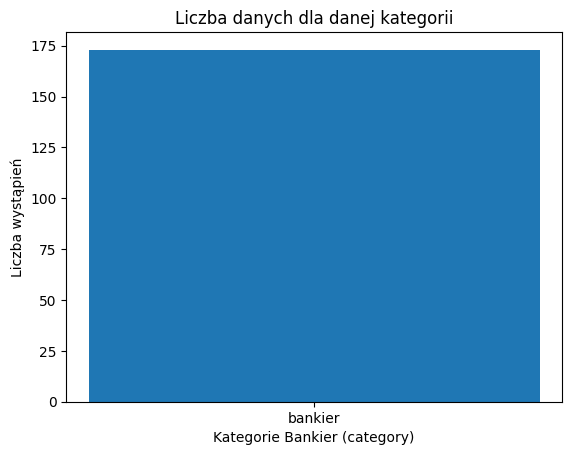

In [54]:
counts = compacted_data[compacted_data['source'] == 'bankier']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Bankier (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

### Kategorie Wykop

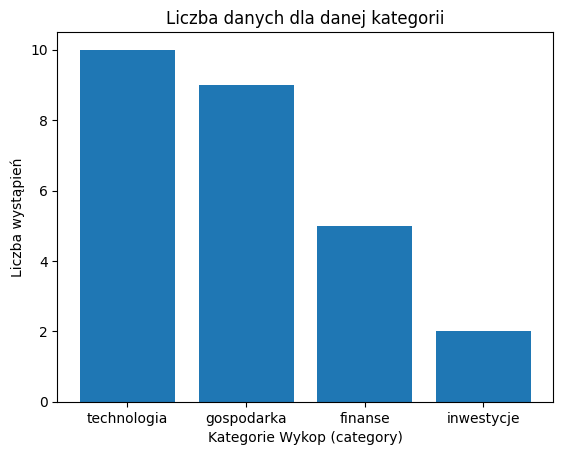

In [55]:
counts = compacted_data[compacted_data['source'] == 'wykop']['category'].value_counts()
plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Wykop (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

## Dane numeryczne

### Kolumna rate

In [56]:
rate_dataset = compacted_data['rate']
print(rate_dataset.value_counts(),'\n')
print('Najwyższa nota:', max(rate_dataset))
print('Najniższa nota:', min(rate_dataset))
print('Najczęstsza nota:', rate_dataset.mode()[0])
print('Mediana:', rate_dataset.median(numeric_only=True))
print('Średnia:', rate_dataset.mean(numeric_only=True))
print('Krzywa ocen:', rate_dataset.skew())

rate
 0.0    264
 2.0     87
 3.0     65
 1.0     24
-3.0     19
-2.0     17
-1.0     16
 4.0     14
 5.0      7
-5.0      7
-6.0      7
 7.0      6
-4.0      4
 6.0      4
-7.0      1
Name: count, dtype: int64 

Najwyższa nota: 7.0
Najniższa nota: -7.0
Najczęstsza nota: 0.0
Mediana: 0.0
Średnia: 0.6328413284132841
Krzywa ocen: -0.2270595890442466


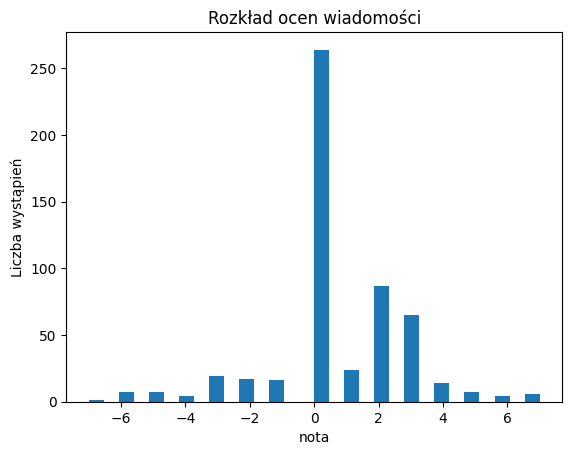

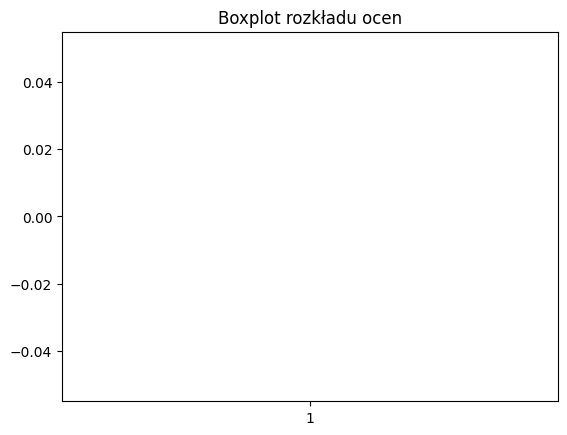

In [67]:

plt.hist(compacted_data['rate'].dropna(), bins=30)
plt.title('Rozkład ocen wiadomości')
plt.xlabel('nota'); plt.ylabel('Liczba wystąpień')
plt.show()
plt.boxplot(compacted_data['rate'])
plt.title('Boxplot rozkładu ocen')
plt.show()

### Rozkład ocen wiadomości pogrupowanych po źródle

In [58]:
df_sources_rates = compacted_data[['source', 'rate']]

pd.crosstab(df_sources_rates['rate'], df_sources_rates['source'])

source,bankier,pap,wykop
rate,,,
-7.0,0,1,0
-6.0,3,4,0
-5.0,3,3,1
-4.0,2,2,0
-3.0,11,7,1
-2.0,4,12,1
-1.0,9,7,0
0.0,81,164,19
1.0,7,17,0


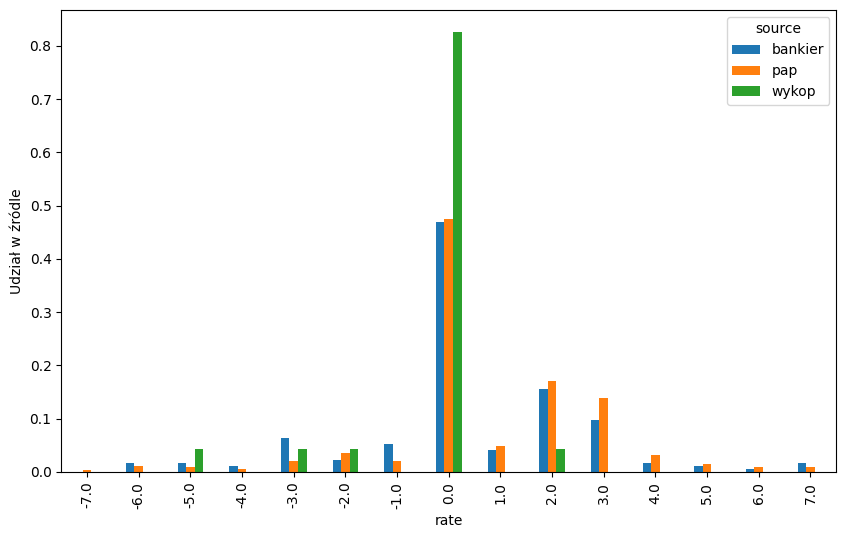

In [59]:
pd.crosstab(compacted_data['rate'], compacted_data['source'], normalize='columns').plot.bar(figsize=(10, 6))
plt.ylabel('Udział w źródle')
plt.show()

In [81]:
price_cols = ['initial price', '+5 min', '+10 min', '+15 min', '+30 min', '+60 min']
print('---------------Którkakolwiek z kolumn cenowych jest pusta-------------')
print(compacted_data[price_cols].isnull().sum())
print('\n-----------------Dystrybucja pustych komórek cenowych-------------')
for col, n in compacted_data[price_cols].isnull().sum().items():
    print(f"{col}: {n}")
print("\n---------------Ilość komórek gdzie wszystkie ceny są brakujace------------")
print(compacted_data[price_cols].isnull().all(axis=1).sum())



---------------Którkakolwiek z kolumn cenowych jest pusta-------------
initial price    40
+5 min           41
+10 min          45
+15 min          48
+30 min          56
+60 min          73
dtype: int64

-----------------Dystrybucja pustych komórek cenowych-------------
initial price: 40
+5 min: 41
+10 min: 45
+15 min: 48
+30 min: 56
+60 min: 73

---------------Ilość komórek gdzie wszystkie ceny są brakujace------------
37


In [85]:
compacted_data = compacted_data.dropna(subset=price_cols, how='all')
print(compacted_data[price_cols].isnull().all(axis=1).sum())


0


Ewidentnie najwięcej brakujących komórek jest w kolumnie +60 min, ponieważ wiele wiadomości było publikowanych na krótko przed zamknieciem giełdy, więc nie było możliwości pobrania ceny akcji z tego czasu

## Korelacja między ceną, a oceną

### Średnia zmiana ceny w zależności od oceny

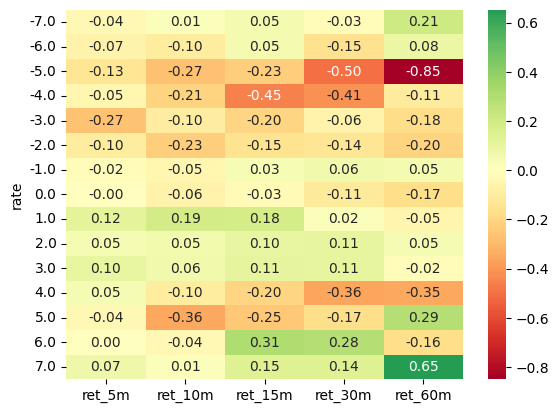

In [60]:
price_cols = ['initial price','+5 min','+10 min','+15 min','+30 min','+60 min']
minutes = [0,5,10,15,30,60]
df = compacted_data.dropna(subset=['rate'] + price_cols).copy()

ret_cols = []
for c, m in zip(price_cols[1:], minutes[1:]):
    col = f'ret_{m}m'
    df[col] = (df[c] / df['initial price'] - 1)*100
    ret_cols.append(col)

sns.heatmap(df.groupby('rate')[ret_cols].mean(), annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.show()


### Mediana zmiany ceny w zależności od oceny

ret_5m 0.121 0.0086
ret_10m 0.101 0.0284
ret_15m 0.07 0.1292
ret_30m 0.098 0.0327
ret_60m 0.079 0.0862


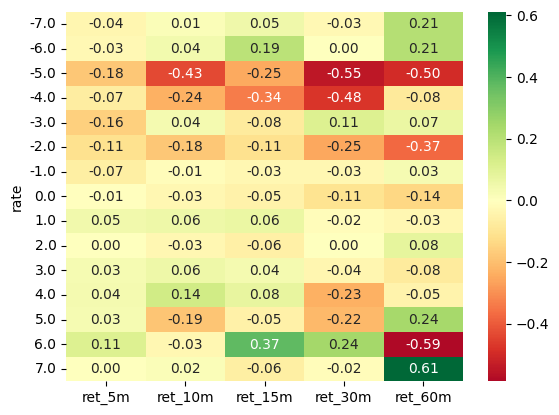

In [ ]:
sns.heatmap(df.groupby('rate')[ret_cols].median(), annot=True, fmt='.2f', cmap='RdYlGn', center=0)

from scipy.stats import spearmanr
for c in ret_cols:
    r, p = spearmanr(df['rate'], df[c])
    print(c, round(r, 3), round(p, 4))
